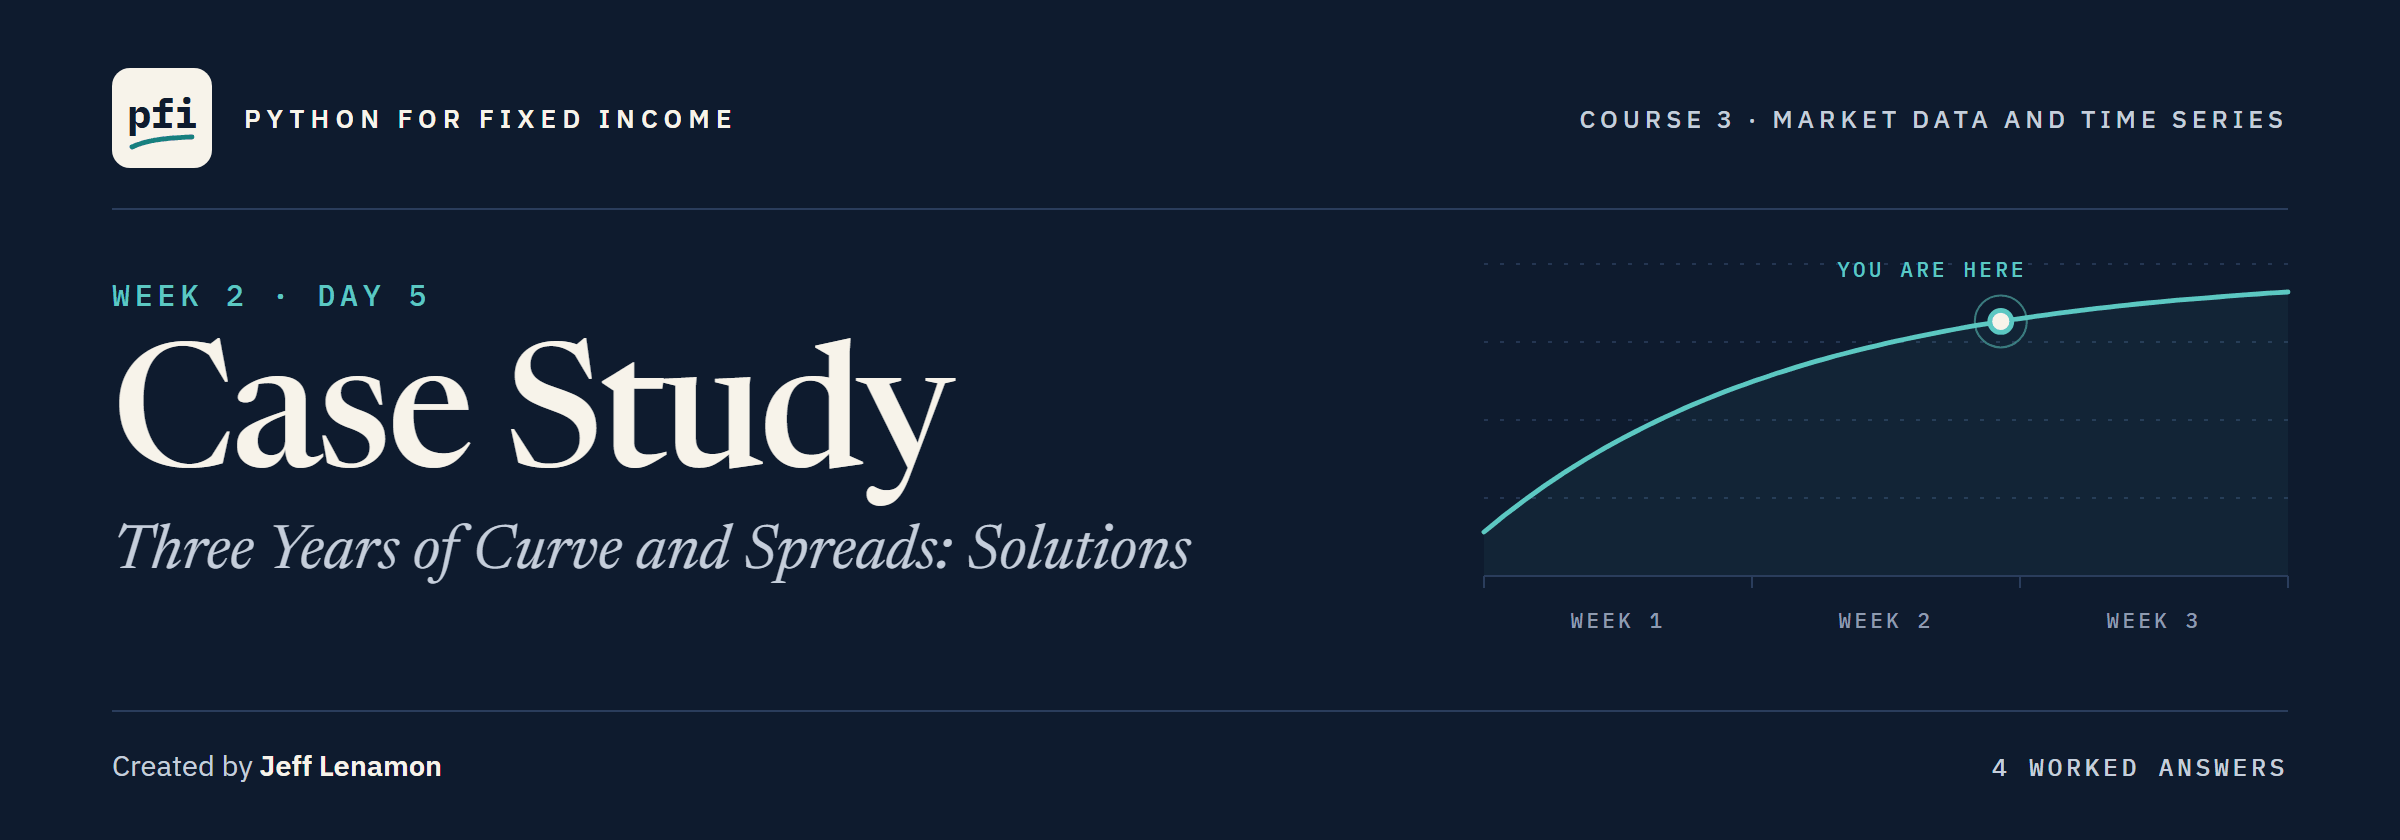

# Case Study: Three Years of Curve and Spreads: Solutions

Week 2, Day 5. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week2/day5/10_case_study_three_years_of_curve_and_spreads_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook leaves it, the twelve series, the second set, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 10 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(10, after=10)

Work folder pfi_course3_10_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 10 left it, 10 commits, tagged week1 and week2


In [2]:
import importlib

import pandas as pd

import marketdata as md

treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
reference = pd.read_csv('course3_excel_reference.csv', parse_dates=['date'], index_col='date',
                        float_precision='round_trip').loc['2026-10-02']

In [3]:
YIELDS = ['3 Mo', '2 Yr', '5 Yr', '10 Yr', '30 Yr']
market = treasury[YIELDS].copy()
market['5s30s'] = md.slope_bp(treasury, '5 Yr', '30 Yr')
market['5s10s30s'] = md.butterfly_bp(treasury, '5 Yr', '10 Yr', '30 Yr')
market = market.join(spreads)
units = {name: 'pct' for name in YIELDS} | {name: 'bp' for name in market.columns[5:]}
second_set = market[['5 Yr', '30 Yr', '5s30s', '5s10s30s', 'hy_spread_bp']]
second_units = {name: units[name] for name in second_set.columns}
print(second_units)

{'5 Yr': 'pct', '30 Yr': 'pct', '5s30s': 'bp', '5s10s30s': 'bp', 'hy_spread_bp': 'bp'}


In [4]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [5]:
ex1_table = md.summary_table(second_set, '2026-09-30', second_units)
ex1_level = ex1_table.loc['5 Yr', 'level']
ex1_hy_rank = ex1_table.loc['hy_spread_bp', 'pct_rank']
ex1_table.round(2)

,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
5 Yr,pct,5.09,3.0,10.0,61.0,2.99,100.00
30 Yr,pct,5.64,5.0,24.0,42.0,3.26,100.00
5s30s,bp,55.00,2.0,14.0,-19.0,-2.24,5.16
5s10s30s,bp,-15.00,-2.0,2.0,9.0,1.90,98.02
hy_spread_bp,bp,334.70,3.6,8.9,19.9,1.09,82.94


Only the date changed; the rows after 2026-09-30 are in `second_set` and play no part.

In [6]:
check('Exercise 1 the 5 Yr on 2026-09-30', ex1_level, 5.09)
check('Exercise 1 the synthetic high yield rank', ex1_hy_rank, 82.93650793650794)

Exercise 1 the 5 Yr on 2026-09-30: correct
Exercise 1 the synthetic high yield rank: correct


### Exercise 2

In [7]:
ex2_table = md.summary_table(second_set, '2026-10-02', second_units, window=63)
ex2_z = ex2_table.loc['hy_spread_bp', 'zscore']
ex2_lowest = ex2_table['pct_rank'].idxmin()
# the 252-row z-scores beside the 63-row ones
ex2_252 = md.summary_table(second_set, '2026-10-02', second_units)
pd.DataFrame({'zscore_63': ex2_table['zscore'], 'zscore_252': ex2_252['zscore']}).round(2)

,zscore_63,zscore_252
series,,
5 Yr,2.08,2.80
30 Yr,2.63,3.08
5s30s,-1.08,-2.07
5s10s30s,2.56,2.58
hy_spread_bp,0.26,0.90


The level and the three changes do not depend on the window; only `zscore` and `pct_rank` do.
A shorter window compares today with a shorter past, so the same level sits in a different place.

In [8]:
check('Exercise 2 the 63-row z-score', ex2_z, 0.25921388996128797)
check('Exercise 2 the lowest 63-row rank', ex2_lowest, '5s30s')

Exercise 2 the 63-row z-score: correct
Exercise 2 the lowest 63-row rank: correct


### Exercise 3

In [9]:
%%writefile -a marketdata.py


def largest_moves(table: pd.DataFrame, n: int, column: str = "chg_1d_bp") -> pd.DataFrame:
    """The n rows of a summary table with the largest moves in `column`, largest first.

    Units: the table's own; column is a change in bp. Convention: rows are ordered by the size of the
    move, its absolute value, so a fall counts as much as a rise. Sizes are rounded to 9 decimals before
    sorting, so binary noise cannot break a tie, and ties keep the table's order (a stable sort).
    Raises ValueError if n is below 1 or column is not a column of the table.
    """
    if n < 1:
        raise ValueError(f"n must be at least 1, not {n}")
    if column not in table.columns:
        raise ValueError(f"{column!r} is not a column of the table")
    # the size of each move, rounded so noise in the last binary digit does not decide the order
    size = table[column].abs().round(9)
    order = size.sort_values(ascending=False, kind="stable").index
    return table.loc[order[:n]]

Appending to marketdata.py


In [10]:
%%writefile -a test_marketdata.py


def test_largest_moves_orders_by_size():
    table = pd.DataFrame({"chg_1d_bp": [2.0, -7.0, 5.0, -5.0]}, index=["a", "b", "c", "d"])
    # a fall of 7 is the largest move; c and d tie at 5 and keep the table's order
    assert list(md.largest_moves(table, 3).index) == ["b", "c", "d"]
    with pytest.raises(ValueError):
        md.largest_moves(table, 0)

Appending to test_marketdata.py


In [11]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........................................                              [100%]
43 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_table = md.summary_table(second_set, '2026-10-02', second_units)
ex3_names = list(md.largest_moves(ex3_table, 2).index)
md.largest_moves(ex3_table, 2).round(2)

,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
5 Yr,pct,5.06,5.0,8.0,52.0,2.80,99.60
5s30s,bp,57.00,-3.0,6.0,-16.0,-2.07,5.95


The function sorts the day's moves by size and says nothing about any series beyond that.

In [13]:
check('Exercise 3 the two largest moves', ex3_names, ['5 Yr', '5s30s'])

Exercise 3 the two largest moves: correct


### Exercise 4: AI check

The bug: `iloc[-(window + 1):]` takes 253 rows, one too many.
The comment, "window rows back from today, plus today itself", counts today twice: the 252 rows already include it.
The fix: `iloc[-window:]`, exactly `window` rows, the last of them today.

In [14]:
def trailing_window(series, as_of, window=252):
    """The last `window` rows of `series` on or before as_of, as_of included."""
    known = series.loc[:as_of]
    # the fix: today is already the last of the `window` rows
    return known.iloc[-window:]


def zscore_as_of(series, as_of, window=252):
    """The z-score of `series` on `as_of`, over the trailing window that ends on as_of.

    Units: none (standard deviations). Convention: only rows on or before as_of are used;
    the window holds `window` rows (252 by default), as_of itself and the window - 1 rows
    before it; sample standard deviation (ddof=1).
    Excel: =STANDARDIZE(x,AVERAGE(window),STDEV.S(window)).
    """
    rows = trailing_window(series, as_of, window)
    # today's value against the mean and sample standard deviation of its window
    return (rows.iloc[-1] - rows.mean()) / rows.std(ddof=1)

In [15]:
ten = treasury['10 Yr']
# the test, from the docstring: 252 rows, and Excel's STANDARDIZE on 2026-10-02
assert len(trailing_window(ten, '2026-10-02')) == 252, 'the window does not hold 252 rows'
excel_z = reference['zscore252_10y']
assert abs(zscore_as_of(ten, '2026-10-02') - excel_z) <= 1e-9, "not Excel's z-score"
print("252 rows, and the z-score equals Excel's STANDARDIZE on 2026-10-02")
ex4_rows = len(trailing_window(ten, '2026-10-02'))
ex4_z = zscore_as_of(ten, '2026-10-02')

252 rows, and the z-score equals Excel's STANDARDIZE on 2026-10-02


An off-by-one window passes every check that only asks whether the number looks reasonable; the length test catches it.

In [16]:
check('Exercise 4 the window length', ex4_rows, 252)
check('Exercise 4 the z-score', ex4_z, 3.075234405274332)

Exercise 4 the window length: correct
Exercise 4 the z-score: correct


[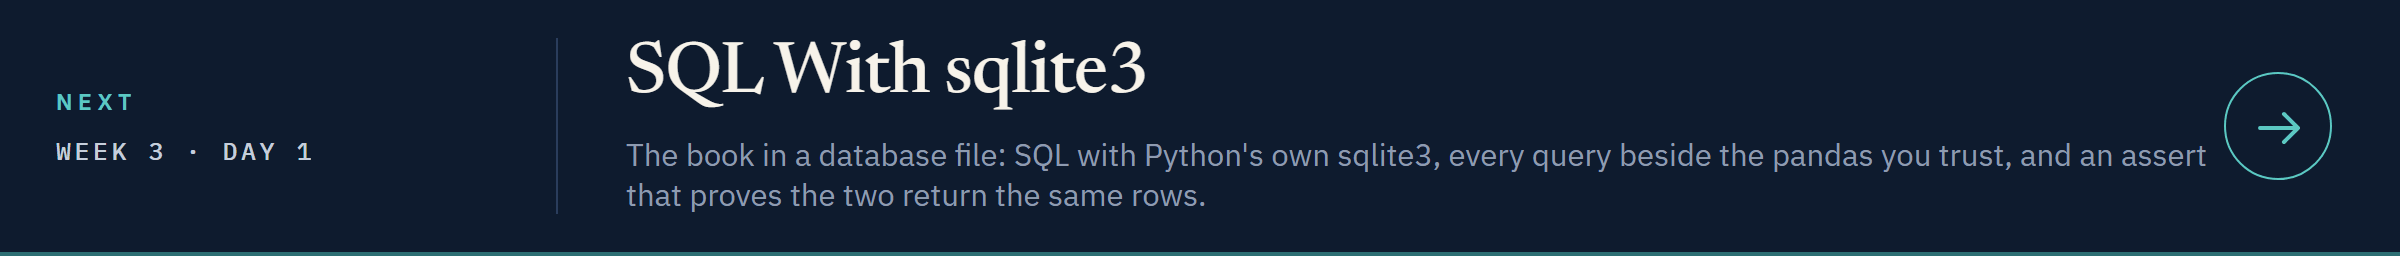](../../week3/day1/11_sql_with_sqlite3.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day1/11_sql_with_sqlite3.ipynb)